In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

ROOT_DIR = Path.cwd().parent

sys.path.append(str(ROOT_DIR))

print("Project root:", ROOT_DIR)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
# Thư viện	Công việc
# sys	Tương tác với môi trường Python
# Path	Xử lý đường dẫn file, thư mục
# numpy	Tính toán ma trận, vector
# pandas	Đọc và xử lý dữ liệu dạng bảng
# matplotlib	Vẽ biểu đồ

Project root: C:\Users\PC\ML-Projects\Linear_Regression
NumPy: 2.4.6
Pandas: 3.1.1


In [3]:
DATA_PATH = Path("../data/house_predict.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("dataset not found")
df = pd.read_csv(DATA_PATH)
print("load data")
print(df.shape)

load data
(1460, 81)


In [4]:
from sklearn.model_selection import train_test_split

# Lấy các feature dạng số, bỏ Id và target
X = df.select_dtypes(include=np.number).drop(
    columns=["Id", "SalePrice"],
    errors="ignore"
)

y = df["SalePrice"].to_numpy().reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
# 1. Import train_test_split
# from sklearn.model_selection import train_test_split
# Ta sử dụng một công cụ có sẵn của Scikit-learn để chia dữ liệu.
# Lưu ý: chúng ta chỉ dùng Scikit-learn để hỗ trợ chia dữ liệu, không dùng nó để huấn luyện Linear Regression.
# 2. Tạo X
# X = df.select_dtypes(include=np.number)
# select_dtypes() lọc các cột theo kiểu dữ liệu.
# include=np.number nghĩa là chỉ lấy các cột có kiểu dữ liệu số.
# Sau đó:
# .drop(columns=["Id", "SalePrice"], errors="ignore")
# Loại bỏ hai cột:
# - Id: mã định danh căn nhà, không dùng làm feature trong phiên bản này.
# - SalePrice: chính là kết quả chúng ta muốn dự đoán.
# Tại sao phải loại SalePrice?
# Vì nếu đưa giá nhà thực tế vào đầu vào, model sẽ nhìn thấy đáp án trước khi dự đoán. Đây là một dạng Data Leakage.
# 3. Tạo y
# y = df["SalePrice"].to_numpy().reshape(-1, 1)
# Đây là biến mục tiêu (Target).Ý nghĩa các tham số:
# - test_size=0.2: giữ lại 20% dữ liệu để kiểm tra.
# - random_state=42: cố định cách chia để có thể tái lập kết quả.
# Tại sao không dùng toàn bộ 1.460 dòng để train?
# Vì nếu model vừa học vừa kiểm tra trên cùng dữ liệu, ta không biết nó có thực sự dự đoán tốt trên những căn nhà chưa từng gặp hay không.

Train: (1168, 36)
Test: (292, 36)


In [5]:
# Impute missing values
X_median = X_train.median()# Tính median của từng cột trong tập train.

X_train = X_train.fillna(X_median)# fillna() thay thế các giá trị bị thiếu bằng median tương ứng của từng feature.
X_test = X_test.fillna(X_median)

# Convert to numpy
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()

# Standardization
X_mean = X_train.mean(axis=0)# mean(axis=0): tính trung bình từng cột.
X_std = X_train.std(axis=0)#std(axis=0): tính độ lệch chuẩn từng cột.

X_std[X_std == 0] = 1

X_train_scaled = (X_train - X_mean) / X_std
X_test_scaled = (X_test - X_mean) / X_std

# Scale target
y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train - y_mean) / y_std

print("Preprocessing completed!")
print("X train:", X_train_scaled.shape)
print("X test:", X_test_scaled.shape)
# Tại sao không tính median trên toàn bộ dataset?
# Vì nếu tính trên cả test, thông tin từ tập kiểm tra đã tham gia vào quá trình preprocessing.
# Đây là một dạng Data Leakage.
# Pandas DataFrame thuận tiện cho xử lý dữ liệu dạng bảng.
# NumPy array thuận tiện cho các phép toán ma trận.
# Tương tự X, chúng ta chuẩn hóa giá nhà.
# Điểm quan trọng: chỉ chuẩn hóa y_train, không dùng y_test để tính mean và std.
# Khi dự đoán, ta sẽ chuyển kết quả về USD bằng:
# y_original = y^_scaled x y_std + y_mean
# Đến đây dữ liệu đã sẵn sàng để đưa vào thuật toán.

Preprocessing completed!
X train: (1168, 36)
X test: (292, 36)


In [6]:
from src.models.linear_regression import LinearRegressionGD

model = LinearRegressionGD(
    learning_rate=0.01,
    epochs=5000
)

model.fit(X_train_scaled, y_train_scaled)# Đưa dữ liệu train vào thuật toán.

print("Training completed!")
print("Final loss:", model.loss_history[-1])# [-1] lấy phần tử cuối cùng của list, tức loss tại epoch cuối cùng.
# 1. Import class
# from src.models.linear_regression import LinearRegressionGD
# Lấy class từ file riêng trong src/.
# 2. Tạo object
# model = LinearRegressionGD(...)
# Lúc này mới chỉ khởi tạo model, chưa học gì cả.
# 3. Train
# Đưa dữ liệu train vào thuật toán.
# Sau 5.000 epoch, model có các trọng số đã được cập nhật.
# 4. Kiểm tra Loss
# model.loss_history[-1]

Training completed!
Final loss: 0.19287823435902013


In [7]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict
y_pred_scaled = model.predict(X_test_scaled)

# Convert predictions về USD
y_pred = y_pred_scaled * y_std + y_mean

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("===== LINEAR REGRESSION EVALUATION =====")
print(f"MAE:  ${mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2:   {r2:.4f}")
# 1. Predict trên test
# y_pred_scaled = model.predict(X_test_scaled)
# Model nhận 292 căn nhà chưa từng dùng để train.
# Nó sử dụng theta đã học để tính ra 292 mức giá dự đoán.
# 2. Chuyển về đơn vị USD
# y_pred = y_pred_scaled * y_std + y_mean
# Lúc train, chúng ta đã chuẩn hóa giá nhà.
# Vì vậy, dự đoán hiện tại vẫn nằm trên thang đo chuẩn hóa.
# Ta cần khôi phục về USD để kết quả dễ hiểu và sử dụng trong thực tế.
# 3. Các chỉ số đánh giá
# Metric	Ý nghĩa	Đơn vị
# MAE	Sai số tuyệt đối trung bình	USD
# MSE	Bình phương sai số trung bình	USD²
# RMSE	Căn bậc hai của MSE	USD
# R²	Khả năng giải thích biến thiên của target	Không đơn vị

===== LINEAR REGRESSION EVALUATION =====
MAE:  $22,978.91
MSE:  1,357,165,229.08
RMSE: $36,839.72
R2:   0.8231


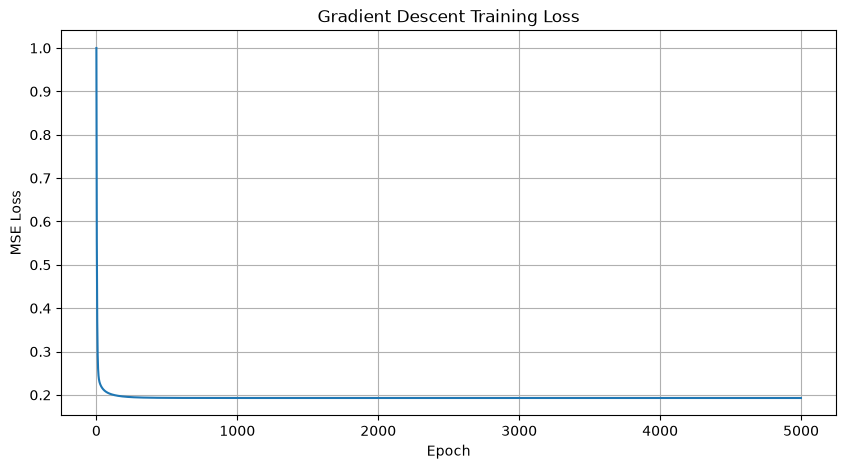

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(model.loss_history)

plt.title("Gradient Descent Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.grid()
plt.show()
# Biểu đồ giúp trả lời:
# - Loss có giảm không?
# - Model có hội tụ không?
# - Loss có dao động bất thường không?
# - Learning rate có quá lớn không?
# Nếu loss giảm rồi ổn định, đó là dấu hiệu thuật toán đang hội tụ.
# Nếu loss tăng liên tục hoặc thành NaN, cần kiểm tra learning rate, dữ liệu và phép tính.

In [9]:
from sklearn.model_selection import train_test_split

# Features
X = df.select_dtypes(include=np.number).drop(
    columns=["Id", "SalePrice"],
    errors="ignore"
)

# Target
y = df["SalePrice"].to_numpy().reshape(-1, 1)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X:", X.shape)
print("y:", y.shape)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X: (1460, 36)
y: (1460, 1)
X_train: (1168, 36)
X_test: (292, 36)
y_train: (1168, 1)
y_test: (292, 1)


In [10]:
import joblib
from pathlib import Path

# 1. Tạo thư mục lưu model
MODEL_DIR = Path("artifacts")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 2. Đóng gói model và preprocessing metadata
model_package = {
    "model": model,
    "y_mean": y_mean,
    "y_std": y_std,
    "feature_columns": X_train.columns.tolist(),
    "model_name": "LinearRegression",
    "target": "SalePrice"
}

# 3. Lưu package
model_path = MODEL_DIR / "house_price_linear.joblib"

joblib.dump(model_package, model_path)

print(f"Model saved successfully: {model_path.resolve()}")
print(f"File size: {model_path.stat().st_size / 1024:.2f} KB")

Model saved successfully: C:\Users\PC\ML-Projects\Linear_Regression\notebook\artifacts\house_price_linear.joblib
File size: 94.07 KB


In [12]:
import numpy as np

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Build pipeline
cv_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# 2. Configure K-Fold
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Run Cross Validation
cv_results = cross_validate(
    cv_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring={
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "r2": "r2"
    },
    return_train_score=True
)

# 4. Convert negative scores to positive
cv_mae = -cv_results["test_mae"]
cv_mse = -cv_results["test_mse"]
cv_rmse = np.sqrt(cv_mse)
cv_r2 = cv_results["test_r2"]

# 5. Display results
print("===== 5-FOLD CROSS VALIDATION =====")

for i in range(5):
    print(
        f"Fold {i+1}: "
        f"MAE=${cv_mae[i]:,.2f} | "
        f"RMSE=${cv_rmse[i]:,.2f} | "
        f"R2={cv_r2[i]:.4f}"
    )

print("\n===== CROSS VALIDATION SUMMARY =====")
print(f"Mean MAE:  ${cv_mae.mean():,.2f}")
print(f"Std MAE:   ${cv_mae.std():,.2f}")
print(f"Mean RMSE: ${cv_rmse.mean():,.2f}")
print(f"Std RMSE:  ${cv_rmse.std():,.2f}")
print(f"Mean R2:   {cv_r2.mean():.4f}")
print(f"Std R2:    {cv_r2.std():.4f}")

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\PC\anaconda3\envs\ml-lab\Lib\site-packages\sklearn\model_selection\_validation.py", line 860, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\PC\anaconda3\envs\ml-lab\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\PC\anaconda3\envs\ml-lab\Lib\site-packages\sklearn\pipeline.py", line 645, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "C:\Users\PC\anaconda3\envs\ml-lab\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    ret

In [13]:
print("===== X_train =====")
print("Type:", type(X_train))
print("Shape:", X_train.shape)

if hasattr(X_train, "dtypes"):
    print("\nData types:")
    print(X_train.dtypes.value_counts())

print("\nMissing values:", X_train.isnull().sum().sum())

print("\n===== y_train =====")
print("Type:", type(y_train))
print("Shape:", y_train.shape)

print("\nMissing values:", y_train.isnull().sum())

print("\n===== SAMPLE DATA =====")
print(X_train.head())
print(y_train.head())

===== X_train =====
Type: <class 'pandas.DataFrame'>
Shape: (1168, 36)

Data types:
int64      33
float64     3
Name: count, dtype: int64

Missing values: 287

===== y_train =====
Type: <class 'numpy.ndarray'>
Shape: (1168, 1)


AttributeError: 'numpy.ndarray' object has no attribute 'isnull'

In [14]:
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_validate

# 1. Recover original target values (USD)
y_train_raw = y_train.ravel() * y_std + y_mean

# 2. Build preprocessing + model pipeline
regression_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# 3. Wrap target scaling inside CV
cv_model = TransformedTargetRegressor(
    regressor=regression_pipeline,
    transformer=StandardScaler()
)

# 4. Configure 5-Fold
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 5. Run Cross Validation
cv_results = cross_validate(
    cv_model,
    X_train,
    y_train_raw,
    cv=kfold,
    scoring={
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "r2": "r2"
    }
)

# 6. Calculate metrics
cv_mae = -cv_results["test_mae"]
cv_mse = -cv_results["test_mse"]
cv_rmse = np.sqrt(cv_mse)
cv_r2 = cv_results["test_r2"]

# 7. Display results
print("===== 5-FOLD CROSS VALIDATION =====")

for i in range(5):
    print(
        f"Fold {i+1}: "
        f"MAE=${cv_mae[i]:,.2f} | "
        f"RMSE=${cv_rmse[i]:,.2f} | "
        f"R2={cv_r2[i]:.4f}"
    )

print("\n===== SUMMARY =====")
print(f"Mean MAE:  ${cv_mae.mean():,.2f}")
print(f"Std MAE:   ${cv_mae.std():,.2f}")
print(f"Mean RMSE: ${cv_rmse.mean():,.2f}")
print(f"Mean R2:   {cv_r2.mean():.4f}")
print(f"Std R2:    {cv_r2.std():.4f}")

===== 5-FOLD CROSS VALIDATION =====
Fold 1: MAE=$1,681,797,978.12 | RMSE=$2,476,799,855.28 | R2=0.8409
Fold 2: MAE=$1,769,585,596.36 | RMSE=$3,060,781,425.25 | R2=0.7317
Fold 3: MAE=$1,815,353,227.67 | RMSE=$3,925,458,244.37 | R2=0.6164
Fold 4: MAE=$1,830,415,402.92 | RMSE=$2,508,160,963.62 | R2=0.8068
Fold 5: MAE=$1,583,607,382.49 | RMSE=$2,207,750,819.54 | R2=0.8451

===== SUMMARY =====
Mean MAE:  $1,736,151,917.51
Std MAE:   $92,195,931.57
Mean RMSE: $2,835,790,261.61
Mean R2:   0.7682
Std R2:    0.0861


In [15]:
print("===== TARGET DEBUG =====")

print("y_train shape:", y_train.shape)
print("y_mean:", y_mean)
print("y_std:", y_std)

print("\nCurrent y_train:")
print("Min:", np.min(y_train))
print("Max:", np.max(y_train))
print("Mean:", np.mean(y_train))

print("\nRecovered y_train_raw:")
print("Min:", np.min(y_train_raw))
print("Max:", np.max(y_train_raw))
print("Mean:", np.mean(y_train_raw))

===== TARGET DEBUG =====
y_train shape: (1168, 1)
y_mean: 181441.5419520548
y_std: 77230.50161542717

Current y_train:
Min: 34900
Max: 745000
Mean: 181441.5419520548

Recovered y_train_raw:
Min: 2695525947.9203606
Max: 57536905145.035194
Mean: 14013002740.375715


In [16]:
# 1. Original target in USD
y_train_raw = y_train.ravel()

# 2. Build pipeline
regression_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# 3. Configure K-Fold
cv_model = TransformedTargetRegressor(
    regressor=regression_pipeline,
    transformer=StandardScaler()
)

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. Cross Validation
cv_results = cross_validate(
    cv_model,
    X_train,
    y_train_raw,
    cv=kfold,
    scoring={
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "r2": "r2"
    }
)

# 5. Metrics
cv_mae = -cv_results["test_mae"]
cv_mse = -cv_results["test_mse"]
cv_rmse = np.sqrt(cv_mse)
cv_r2 = cv_results["test_r2"]

# 6. Results
print("===== 5-FOLD CROSS VALIDATION =====")

for i in range(5):
    print(
        f"Fold {i+1}: "
        f"MAE=${cv_mae[i]:,.2f} | "
        f"RMSE=${cv_rmse[i]:,.2f} | "
        f"R2={cv_r2[i]:.4f}"
    )

print("\n===== SUMMARY =====")
print(f"Mean MAE:  ${cv_mae.mean():,.2f}")
print(f"Std MAE:   ${cv_mae.std():,.2f}")
print(f"Mean RMSE: ${cv_rmse.mean():,.2f}")
print(f"Mean R2:   {cv_r2.mean():.4f}")
print(f"Std R2:    {cv_r2.std():.4f}")

===== 5-FOLD CROSS VALIDATION =====
Fold 1: MAE=$21,776.34 | RMSE=$32,070.23 | R2=0.8409
Fold 2: MAE=$22,913.04 | RMSE=$39,631.77 | R2=0.7317
Fold 3: MAE=$23,505.65 | RMSE=$50,827.82 | R2=0.6164
Fold 4: MAE=$23,700.68 | RMSE=$32,476.30 | R2=0.8068
Fold 5: MAE=$20,504.95 | RMSE=$28,586.51 | R2=0.8451

===== SUMMARY =====
Mean MAE:  $22,480.13
Std MAE:   $1,193.78
Mean RMSE: $36,718.53
Mean R2:   0.7682
Std R2:    0.0861


In [17]:
import numpy as np

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

# 1. Create baseline model
baseline_model = DummyRegressor(strategy="mean")

# 2. Run 5-Fold Cross Validation
baseline_results = cross_validate(
    baseline_model,
    X_train,
    y_train_raw,
    cv=kfold,
    scoring={
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "r2": "r2"
    }
)

# 3. Calculate metrics
baseline_mae = -baseline_results["test_mae"]
baseline_mse = -baseline_results["test_mse"]
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = baseline_results["test_r2"]

# 4. Display results
print("===== BASELINE MODEL =====")

for i in range(5):
    print(
        f"Fold {i+1}: "
        f"MAE=${baseline_mae[i]:,.2f} | "
        f"RMSE=${baseline_rmse[i]:,.2f} | "
        f"R2={baseline_r2[i]:.4f}"
    )

print("\n===== BASELINE SUMMARY =====")
print(f"Mean MAE:  ${baseline_mae.mean():,.2f}")
print(f"Mean RMSE: ${baseline_rmse.mean():,.2f}")
print(f"Mean R2:   {baseline_r2.mean():.4f}")

# 5. Compare with Linear Regression
print("\n===== MODEL COMPARISON =====")
print(f"Linear Regression MAE: ${cv_mae.mean():,.2f}")
print(f"Baseline MAE:           ${baseline_mae.mean():,.2f}")

improvement = (
    (baseline_mae.mean() - cv_mae.mean())
    / baseline_mae.mean()
) * 100

print(f"MAE Improvement: {improvement:.2f}%")

===== BASELINE MODEL =====
Fold 1: MAE=$59,576.84 | RMSE=$80,423.49 | R2=-0.0006
Fold 2: MAE=$58,663.61 | RMSE=$76,575.01 | R2=-0.0018
Fold 3: MAE=$56,690.29 | RMSE=$82,224.43 | R2=-0.0039
Fold 4: MAE=$53,296.43 | RMSE=$73,940.98 | R2=-0.0017
Fold 5: MAE=$53,363.99 | RMSE=$72,636.63 | R2=-0.0001

===== BASELINE SUMMARY =====
Mean MAE:  $56,318.23
Mean RMSE: $77,160.11
Mean R2:   -0.0016

===== MODEL COMPARISON =====
Linear Regression MAE: $22,480.13
Baseline MAE:           $56,318.23
MAE Improvement: 60.08%


In [18]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_validate

alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_results = []

for alpha in alphas:

    # Build Ridge pipeline
    ridge_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha))
    ])

    ridge_cv_model = TransformedTargetRegressor(
        regressor=ridge_pipeline,
        transformer=StandardScaler()
    )

    # Cross Validation
    scores = cross_validate(
        ridge_cv_model,
        X_train,
        y_train_raw,
        cv=kfold,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        }
    )

    ridge_results.append({
        "alpha": alpha,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": np.sqrt(-scores["test_mse"]).mean(),
        "R2": scores["test_r2"].mean()
    })

# Display results
print("===== RIDGE CROSS VALIDATION =====")

for result in ridge_results:
    print(
        f"Alpha={result['alpha']:>7} | "
        f"MAE=${result['MAE']:,.2f} | "
        f"RMSE=${result['RMSE']:,.2f} | "
        f"R2={result['R2']:.4f}"
    )

===== RIDGE CROSS VALIDATION =====
Alpha=   0.01 | MAE=$22,480.03 | RMSE=$36,718.43 | R2=0.7682
Alpha=    0.1 | MAE=$22,479.09 | RMSE=$36,717.53 | R2=0.7682
Alpha=      1 | MAE=$22,469.76 | RMSE=$36,708.68 | R2=0.7683
Alpha=     10 | MAE=$22,382.38 | RMSE=$36,629.35 | R2=0.7694
Alpha=    100 | MAE=$21,910.38 | RMSE=$36,314.39 | R2=0.7741
Alpha=   1000 | MAE=$22,573.27 | RMSE=$38,133.58 | R2=0.7543


In [19]:
alphas = [30, 50, 75, 100, 150, 200, 300, 500]

fine_tune_results = []

for alpha in alphas:
    ridge_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha))
    ])

    ridge_cv_model = TransformedTargetRegressor(
        regressor=ridge_pipeline,
        transformer=StandardScaler()
    )

    scores = cross_validate(
        ridge_cv_model,
        X_train,
        y_train_raw,
        cv=kfold,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        }
    )

    mae_scores = -scores["test_mae"]
    rmse_scores = np.sqrt(-scores["test_mse"])
    r2_scores = scores["test_r2"]

    fine_tune_results.append({
        "alpha": alpha,
        "MAE_mean": mae_scores.mean(),
        "MAE_std": mae_scores.std(),
        "RMSE_mean": rmse_scores.mean(),
        "R2_mean": r2_scores.mean()
    })

fine_tune_results = sorted(
    fine_tune_results,
    key=lambda x: x["MAE_mean"]
)

print("===== RIDGE FINE-TUNING =====")

for result in fine_tune_results:
    print(
        f"Alpha={result['alpha']:>4} | "
        f"MAE=${result['MAE_mean']:,.2f} | "
        f"MAE Std=${result['MAE_std']:,.2f} | "
        f"RMSE=${result['RMSE_mean']:,.2f} | "
        f"R2={result['R2_mean']:.4f}"
    )

===== RIDGE FINE-TUNING =====
Alpha= 300 | MAE=$21,737.84 | MAE Std=$1,175.66 | RMSE=$36,479.03 | R2=0.7733
Alpha= 200 | MAE=$21,746.15 | MAE Std=$1,129.56 | RMSE=$36,337.33 | R2=0.7745
Alpha= 150 | MAE=$21,804.90 | MAE Std=$1,122.59 | RMSE=$36,302.59 | R2=0.7746
Alpha= 500 | MAE=$21,874.18 | MAE Std=$1,219.49 | RMSE=$36,887.40 | R2=0.7689
Alpha= 100 | MAE=$21,910.38 | MAE Std=$1,121.61 | RMSE=$36,314.39 | R2=0.7741
Alpha=  75 | MAE=$21,989.82 | MAE Std=$1,124.17 | RMSE=$36,349.16 | R2=0.7735
Alpha=  50 | MAE=$22,097.92 | MAE Std=$1,134.02 | RMSE=$36,414.66 | R2=0.7725
Alpha=  30 | MAE=$22,221.12 | MAE Std=$1,151.59 | RMSE=$36,499.78 | R2=0.7712


In [20]:
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Build final pipeline
final_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=200))
])

# 2. Handle target scaling automatically
final_model = TransformedTargetRegressor(
    regressor=final_pipeline,
    transformer=StandardScaler()
)

# 3. Train on the entire training set
final_model.fit(X_train, y_train_raw)

# 4. Predict on untouched test set
y_pred = final_model.predict(X_test)

# 5. Evaluate
y_test_raw = y_test.ravel()

mae = mean_absolute_error(y_test_raw, y_pred)
mse = mean_squared_error(y_test_raw, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_raw, y_pred)

print("===== FINAL MODEL: RIDGE REGRESSION =====")
print(f"Alpha: 200")
print(f"MAE:  ${mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R2:   {r2:.4f}")

===== FINAL MODEL: RIDGE REGRESSION =====
Alpha: 200
MAE:  $22,263.91
MSE:  1,390,031,670.60
RMSE: $37,283.13
R2:   0.8188


In [21]:
import pandas as pd
import numpy as np

# Build prediction report
error_report = pd.DataFrame({
    "Actual_Price": y_test_raw,
    "Predicted_Price": y_pred
})

error_report["Residual"] = (
    error_report["Actual_Price"] -
    error_report["Predicted_Price"]
)

error_report["Absolute_Error"] = (
    error_report["Residual"].abs()
)

error_report["Error_Percent"] = (
    error_report["Absolute_Error"] /
    error_report["Actual_Price"] * 100
)

# Show 10 predictions with largest errors
worst_predictions = error_report.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

print("===== 10 WORST PREDICTIONS =====")
display(worst_predictions.round(2))

print("\n===== ERROR DISTRIBUTION =====")
print(f"Median Absolute Error: ${error_report['Absolute_Error'].median():,.2f}")
print(f"90th Percentile Error: ${error_report['Absolute_Error'].quantile(0.9):,.2f}")
print(f"Maximum Error:         ${error_report['Absolute_Error'].max():,.2f}")

===== 10 WORST PREDICTIONS =====


,Actual_Price,Predicted_Price,Residual,Absolute_Error,Error_Percent
139,755000,448476.73,306523.27,306523.27,40.60
74,611657,377497.70,234159.30,234159.30,38.28
168,556581,338150.82,218430.18,218430.18,39.24
270,465000,330895.51,134104.49,134104.49,28.84
260,395000,289556.05,105443.95,105443.95,26.69
48,451950,352476.99,99473.01,99473.01,22.01
140,403000,305276.99,97723.01,97723.01,24.25
6,311500,224374.22,87125.78,87125.78,27.97
243,438780,367121.26,71658.74,71658.74,16.33
278,143000,209805.78,-66805.78,66805.78,46.72



===== ERROR DISTRIBUTION =====
Median Absolute Error: $16,923.33
90th Percentile Error: $43,062.61
Maximum Error:         $306,523.27


In [22]:
display(
    worst_predictions[
        [
            "Actual_Price",
            "Predicted_Price",
            "Residual",
            "Absolute_Error",
            "Error_Percent"
        ]
    ].round(2)
)

,Actual_Price,Predicted_Price,Residual,Absolute_Error,Error_Percent
139,755000,448476.73,306523.27,306523.27,40.60
74,611657,377497.70,234159.30,234159.30,38.28
168,556581,338150.82,218430.18,218430.18,39.24
270,465000,330895.51,134104.49,134104.49,28.84
260,395000,289556.05,105443.95,105443.95,26.69
48,451950,352476.99,99473.01,99473.01,22.01
140,403000,305276.99,97723.01,97723.01,24.25
6,311500,224374.22,87125.78,87125.78,27.97
243,438780,367121.26,71658.74,71658.74,16.33
278,143000,209805.78,-66805.78,66805.78,46.72


In [23]:
# Get original test features for the worst predictions
worst_indices = worst_predictions.index

worst_houses = X_test.loc[worst_indices].copy()

# Add actual and predicted prices
worst_houses["Actual_Price"] = error_report.loc[
    worst_indices, "Actual_Price"
]

worst_houses["Predicted_Price"] = error_report.loc[
    worst_indices, "Predicted_Price"
]

worst_houses["Absolute_Error"] = error_report.loc[
    worst_indices, "Absolute_Error"
]

# Sort by actual price
worst_houses = worst_houses.sort_values(
    by="Actual_Price",
    ascending=False
)

display(worst_houses)

KeyError: '[139, 74, 260, 48, 140, 6, 243, 278] not in index'

In [24]:
import joblib
from pathlib import Path

# Create model directory
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save trained model
model_path = model_dir / "house_price_ridge.joblib"

joblib.dump(final_model, model_path)

print(f"Model saved at: {model_path.resolve()}")
print(f"Model size: {model_path.stat().st_size / 1024:.2f} KB")

Model saved at: C:\Users\PC\ML-Projects\Linear_Regression\notebook\models\house_price_ridge.joblib
Model size: 4.54 KB


In [25]:
# Load model from disk
loaded_model = joblib.load(model_path)

# Predict using loaded model
loaded_predictions = loaded_model.predict(X_test)

# Compare with original predictions
max_diff = np.max(np.abs(loaded_predictions - y_pred))

print("===== MODEL VERIFICATION =====")
print(f"Original prediction: {y_pred[0]:,.2f} USD")
print(f"Loaded prediction:   {loaded_predictions[0]:,.2f} USD")
print(f"Maximum difference:  {max_diff:.10f}")
print(f"Verification: {'PASSED' if np.allclose(y_pred, loaded_predictions) else 'FAILED'}")

===== MODEL VERIFICATION =====
Original prediction: 149,291.13 USD
Loaded prediction:   149,291.13 USD
Maximum difference:  0.0000000000
Verification: PASSED


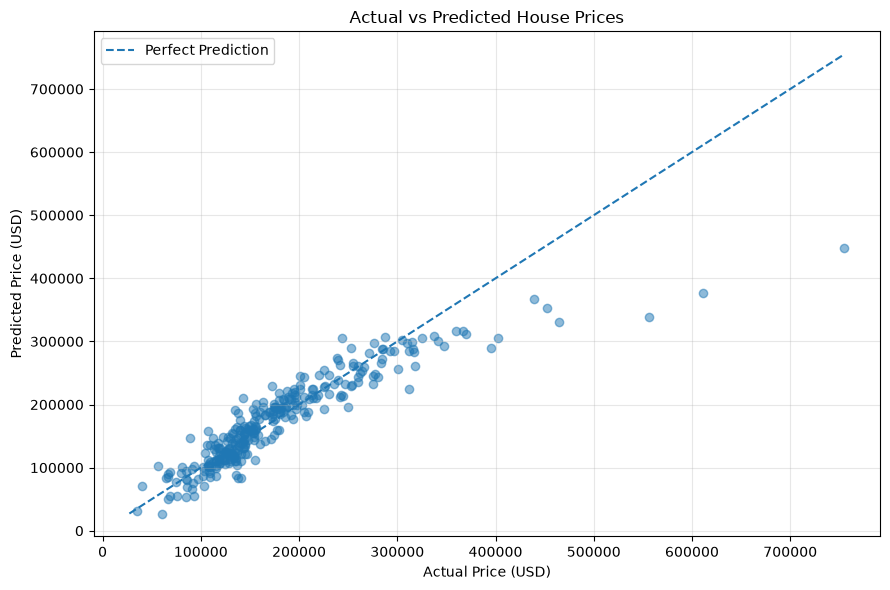

In [26]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

# Vẽ các điểm dự đoán
plt.scatter(
    y_test_raw,
    y_pred,
    alpha=0.5
)

# Đường dự đoán hoàn hảo: Actual = Predicted
min_price = min(y_test_raw.min(), y_pred.min())
max_price = max(y_test_raw.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

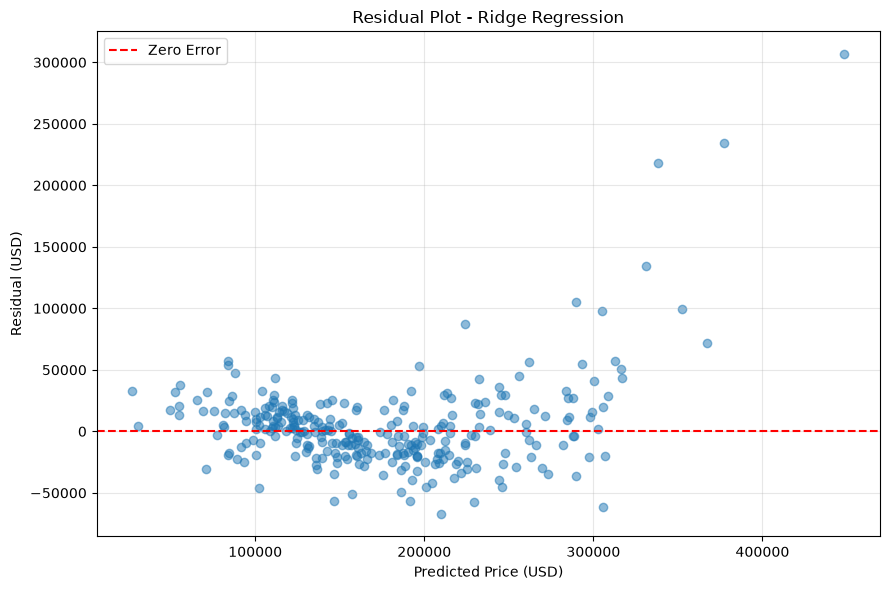

In [27]:
import matplotlib.pyplot as plt

residuals = y_test_raw - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Predicted Price (USD)")
plt.ylabel("Residual (USD)")
plt.title("Residual Plot - Ridge Regression")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

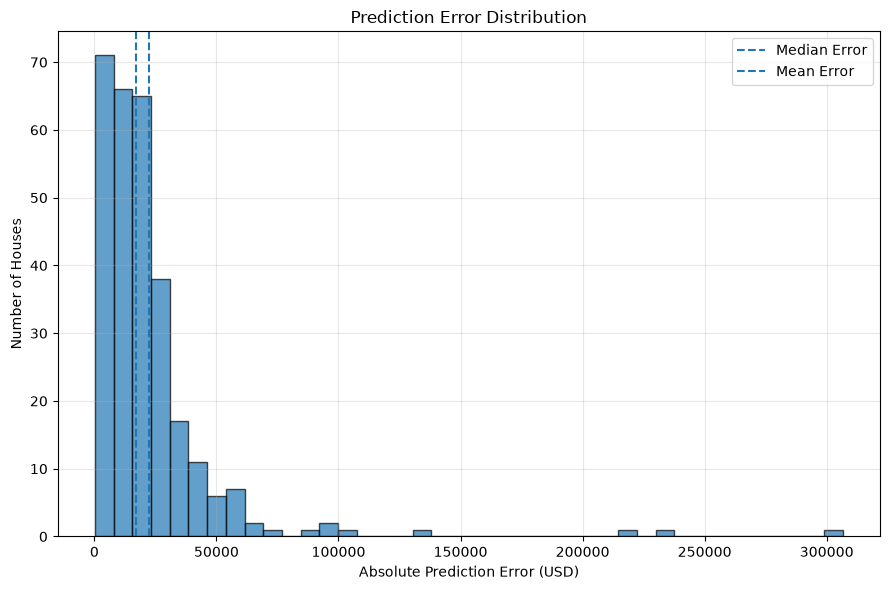

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.hist(
    error_report["Absolute_Error"],
    bins=40,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    error_report["Absolute_Error"].median(),
    linestyle="--",
    label="Median Error"
)

plt.axvline(
    error_report["Absolute_Error"].mean(),
    linestyle="--",
    label="Mean Error"
)

plt.xlabel("Absolute Prediction Error (USD)")
plt.ylabel("Number of Houses")
plt.title("Prediction Error Distribution")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

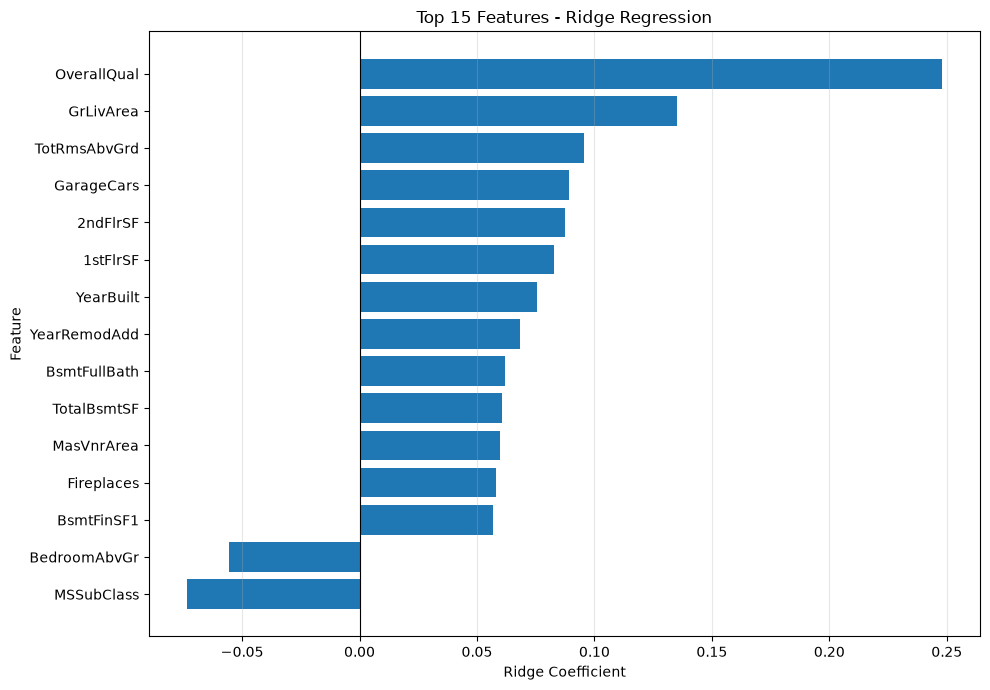

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Lấy hệ số từ Ridge bên trong pipeline
coefficients = final_model.regressor_.named_steps["model"].coef_

# Ghép hệ số với tên feature
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients
})

# Chọn 15 feature có hệ số lớn nhất theo trị tuyệt đối
top_features = (
    coef_df.assign(Abs_Coefficient=coef_df["Coefficient"].abs())
    .nlargest(15, "Abs_Coefficient")
    .sort_values("Coefficient")
)

# Vẽ biểu đồ
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)
plt.xlabel("Ridge Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Features - Ridge Regression")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

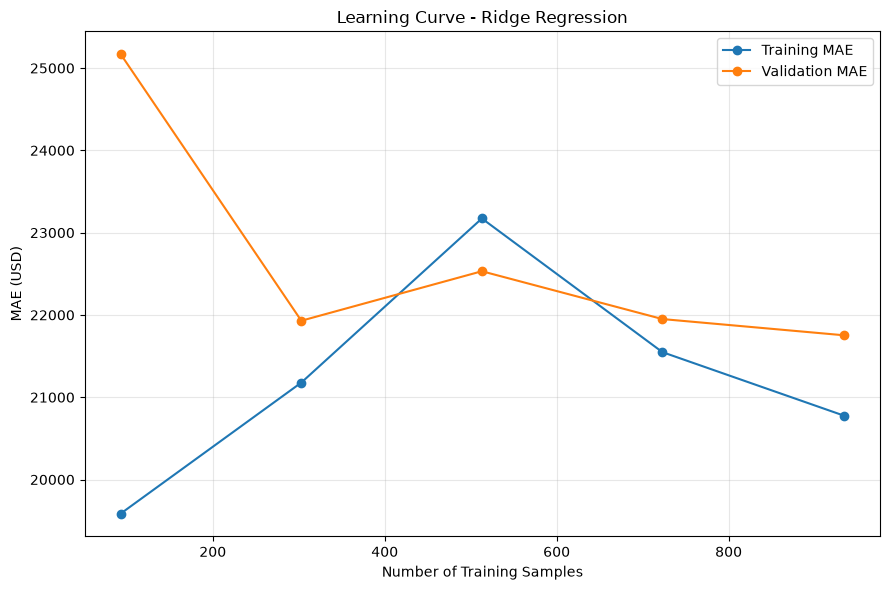

In [31]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=final_model,
    X=X_train,
    y=y_train_raw,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=kfold,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Chuyển MAE từ số âm sang số dương
train_mae = -train_scores.mean(axis=1)
validation_mae = -validation_scores.mean(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(train_sizes, train_mae, marker="o", label="Training MAE")
plt.plot(train_sizes, validation_mae, marker="o", label="Validation MAE")

plt.xlabel("Number of Training Samples")
plt.ylabel("MAE (USD)")
plt.title("Learning Curve - Ridge Regression")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()